In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from skophys.utils import rolling_percentile

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [3]:
%matplotlib inline

In [4]:
path = "./demo_movie_mcorr.tiff"
movie = tifffile.imread(path)

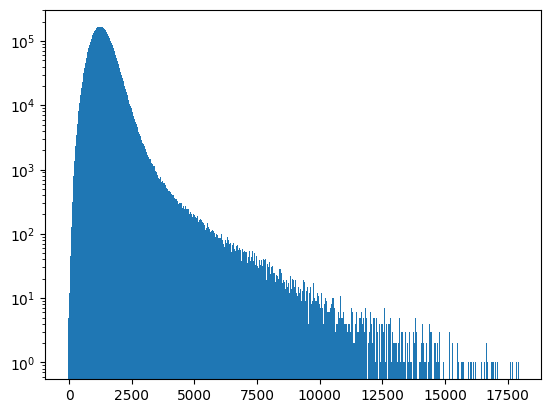

In [5]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [141]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [7]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [8]:
filt_movie = rolling_percentile(movie, window_size=10, quantile=5)

In [9]:
iw_movie.set_data(filt_movie, reset_indices=False)

In [142]:
iw_movie.set_data(Y.reshape(movie.shape[2], movie.shape[1], movie.shape[0]).T, reset_indices=False)

In [10]:
from sklearn.preprocessing import RobustScaler

In [11]:
filt_movie.shape

(2000, 60, 80)

In [12]:
Y = filt_movie.T.reshape(np.prod(filt_movie.shape[1:]), filt_movie.shape[0])

In [13]:
ss = RobustScaler()

In [14]:
Y = ss.fit_transform(Y.T)
Y = Y.T

In [15]:
Y

array([[-0.7821479 , -0.7821479 , -0.7821479 , ...,  0.5978306 ,
         2.2427278 , -4.4442434 ],
       [-0.7046851 , -0.7046851 , -0.7046851 , ...,  2.5724094 ,
         2.687321  , -4.47395   ],
       [-0.6964363 , -0.6964363 , -0.6964363 , ...,  3.564672  ,
         3.5139759 , -4.058582  ],
       ...,
       [-0.7166553 , -0.7166553 , -0.7166553 , ...,  1.5806742 ,
         1.564576  , -3.1470845 ],
       [-0.5962199 , -0.5962199 , -0.5962199 , ...,  1.2364476 ,
         1.3647544 , -3.3675256 ],
       [-0.66623455, -0.66623455, -0.29150748, ...,  1.3213052 ,
         2.8479884 , -3.2686212 ]], dtype=float32)

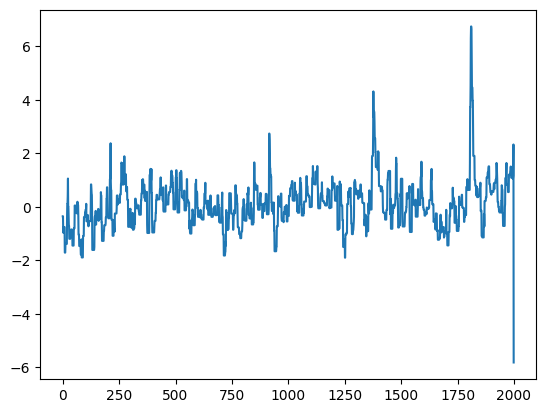

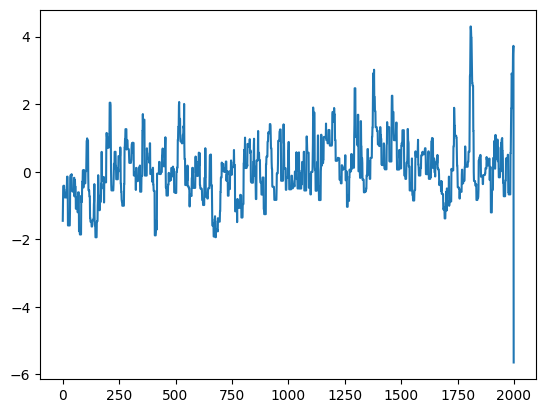

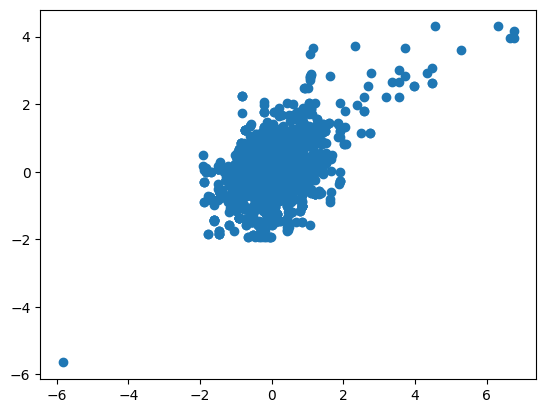

In [16]:
i1 = 1202
i2 = 1203

u = Y[i1]
v = Y[i2]

plt.plot(u)
plt.show()
plt.plot(v)
plt.show()

plt.scatter(Y[i1, :], Y[i2, :])
plt.show()
# plt.scatter(projections[:, 0], projections[:, 1])

In [17]:
Y.shape

(4800, 2000)

In [18]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [19]:
@njit(parallel=True)
def get_distances(
    i: int, 
    Y: np.ndarray, 
    ysum: np.ndarray, 
    projections: np.ndarray,
    output: np.ndarray
):
    for j in prange(Y.shape[0]):
        i_dot_j = np.dot(Y[i], Y[j])
        i_dot_i = np.dot(Y[i], Y[i])
        m = (i_dot_j - 1 / Y.shape[1] * ysum[i] * ysum[j]) / (i_dot_i - 1 / Y.shape[1] * ysum[i]**2)
        
        v1 = np.array([m, 1])

        x = Y[i, :]
        y = Y[j, :]
        
        # Step 1: Calculate means of x and y
        x_mean = np.mean(x)
        y_mean = np.mean(y)
        
        v1[0] += x_mean
        v1[1] += y_mean

        denom = np.sqrt(v1.sum())
        v1[0] = v1[0] / denom
        v1[1] = v1[1] / denom

        v1 /= np.sqrt(np.sum(v1**2))
        
        X = np.zeros((x.size, 2))
        X[:, 0] = x
        X[:, 1] = y
        
        projections_pre = (X @ v1)
        
        projections[j, :, 0] = projections_pre * v1[0]
        projections[j, :, 1] = projections_pre * v1[1]

        orthogonal_distances = X - projections[j]  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
        # orthogonal_distances = orthogonal_distances**2
        
        # # # Sum of orthogonal distances
        # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000

        output[j] = s**2

In [20]:
ysum = np.sum(Y, axis=1)
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))

In [25]:
get_distances(
    2500,
    Y,
    ysum,
    projections,
    output_matrix
)

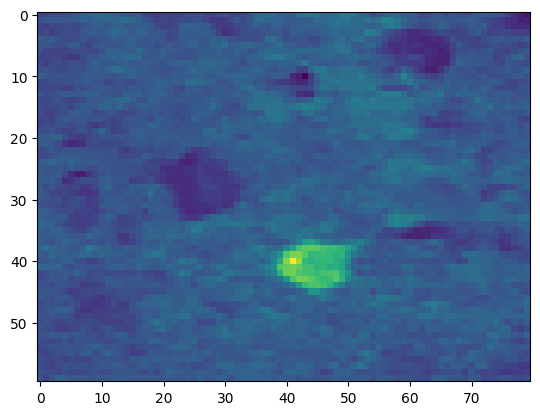

In [26]:
plt.imshow(output_matrix.reshape(movie.shape[2], movie.shape[1]).T, cmap="viridis_r")
plt.show()

In [27]:
projections.shape

(4800, 2000, 2)

In [28]:
std = filt_movie.std(axis=0)

In [29]:
iw = fpl.ImageWidget([std, np.zeros(std.shape)], cmap="viridis")

pixel_index_A = 0
projections = np.zeros((*Y.shape, 2))

pixel_A_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="magenta")
pixel_B_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="cyan")

@iw.managed_graphics[0].add_event_handler("double_click")
def update_distance_image(ev):
    global pixel_index_A
    global projections
    
    col, row = ev.pick_info["index"]

    i = np.ravel_multi_index((col, row), (movie.shape[2], movie.shape[1]))
    
    pixel_index_A = i

    pixel_A_pt.data[0, 0] = col
    pixel_A_pt.data[0, 1] = row
    
    output_matrix = np.zeros((Y.shape[0],))
    projections = np.zeros((*Y.shape, 2))
    get_distances(
        i,
        Y,
        ysum,
        projections,
        output_matrix
    )
    
    iw.managed_graphics[1].data = output_matrix.reshape(movie.shape[2], movie.shape[1]).T
    iw.reset_vmin_vmax()


fig_s = fpl.Figure(shape=(1, 2))

scatter_corr = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors=(1, 0.7, 0, 0.3), alpha=0.3)
scatter_proj = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors="r", alpha=0.3)
fig_s[0, 0].axes.colors = ("magenta", "cyan", "w")

line_p1 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="magenta", alpha=0.3)
line_p2 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="cyan", alpha=0.3)

selector_time = line_p1.add_linear_selector()

@iw.managed_graphics[1].add_event_handler("double_click")
def update_scatters(ev):
    u = Y[pixel_index_A]

    col, row = ev.pick_info["index"]

    j = np.ravel_multi_index((col, row), (movie.shape[2], movie.shape[1]))
    v = Y[j]

    pixel_B_pt.data[0, 0] = col
    pixel_B_pt.data[0, 1] = row
    
    scatter_corr.data[:, :-1] = np.column_stack([u, v])
    scatter_proj.data[:, :-1] = projections[j]
    fig_s[0, 0].auto_scale(maintain_aspect=False)

    line_p1.data[:, 1] = u
    line_p2.data[:, 1] = v
    fig_s[0, 1].auto_scale(maintain_aspect=False)

@selector_time.add_event_handler("selection")
def update_selected_time(ev):
    t = ev.get_selected_index()
    scatter_corr.colors = (1, 0.7, 0, 0.3)
    scatter_corr.sizes = 4
    
    scatter_corr.colors[t] = "w"
    scatter_corr.sizes[t] = 20


iw.cmap = ["viridis", "viridis_r"]

VBox([iw.show(), fig_s.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

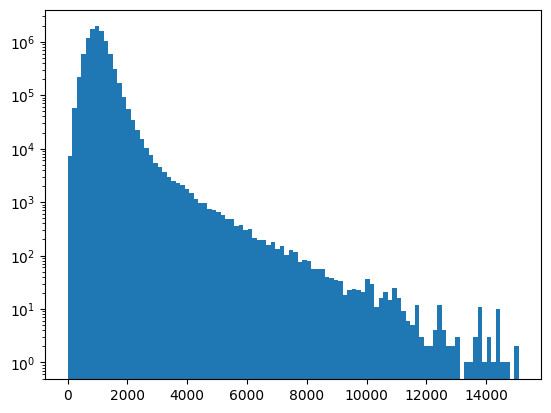

In [125]:
plt.hist(filt_movie.ravel(), bins=100)
plt.semilogy()
plt.show()

In [256]:
iw.managed_graphics[1].vmax = np.percentile(iw.managed_graphics[1].data[:], 3)

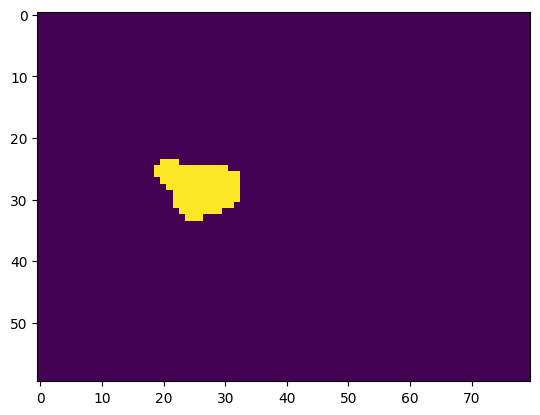

In [262]:
plt.imshow(iw.managed_graphics[1].data[:] < np.percentile(iw.managed_graphics[1].data[:], 2))

In [257]:
np.percentile(iw.managed_graphics[1].data[:], 3)

np.float32(2577592.2)

In [97]:
i_col, i_row, _ =  pixel_A_pt.data[0]
i_col, i_row

(np.float32(24.0), np.float32(28.0))

In [98]:
j_col, j_row, _ = pixel_B_pt.data[0]
j_col, j_row

(np.float32(26.0), np.float32(23.0))

# Plot time series of the two pixels, linear region selector to highlight scatter point
# click on scatter point, set linear region selector timepoint

In [31]:
Y.shape

(4800, 2000)

In [32]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [37]:
for i in tqdm(range(Y.shape[0])):
    output_matrix = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        ysum,
        projections,
        output_matrix
    )
    dist_cov[i] = output_matrix

100%|█████████████████████████████████████████████████████████████████████| 4800/4800 [01:11<00:00, 67.12it/s]


RFBOutputContext()

JupyterWgpuCanvas(css_height='400px', css_width='700px')
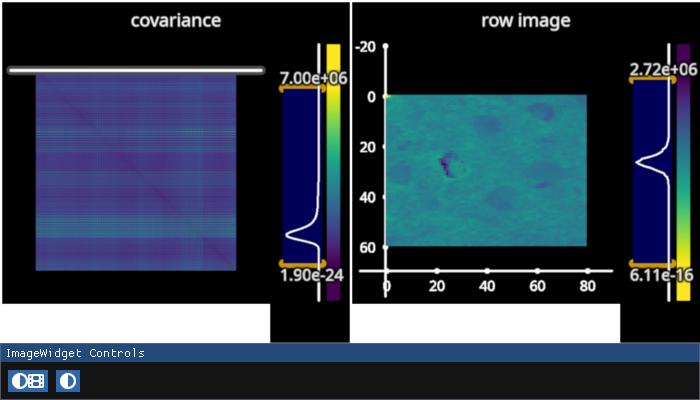

In [47]:
img = dist_cov[0].reshape(movie.shape[2], movie.shape[1])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}
iw_cov = fpl.ImageWidget(
    data=[dist_cov, img.T],
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

iw_cov.cmap = ["viridis", "viridis_r"]

selector_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    img = dist_cov[ix].reshape(movie.shape[2], movie.shape[1])
    iw_cov.managed_graphics[1].data = img.T

iw_cov.show()

In [88]:
Y.shape

(4800, 2000)

In [265]:
clusters = np.zeros((100, Y.shape[0]), dtype=np.int32)

In [285]:
for i in tqdm(range(1100, 2200)):
    # see if this pixel is never active
    if np.count_nonzero(Y[i] > 5) < 3:
        continue
    
    threshold = np.percentile(dist_cov[i], 3)

    # does this pixel already belong to any existing cluster(s)
    cluster_memberships = np.where(clusters[:, i] != 0)[0]
    if cluster_memberships.size == 0:
        # create new cluster index for this pixel and keep if matches are found
        for n in range(clusters.shape[0]):
            if (clusters[n, :] == 0).all():
                break
                
        membership_indices = np.array([n])
    else:
        membership_indices = cluster_memberships
    
    for j in range(1100, 2200):
        # check if pixel is active
        if np.count_nonzero(Y[j] > 5) < 3:
            continue

        if dist_cov[i, j] < threshold:
            # add i and j to this cluster
            clusters[membership_indices, j] = 1
            flag_match = True
            
    if flag_match:
        clusters[membership_indices, i] = 1

100%|███████████████████████████████████████████████████████████████████| 1100/1100 [00:00<00:00, 1994.39it/s]


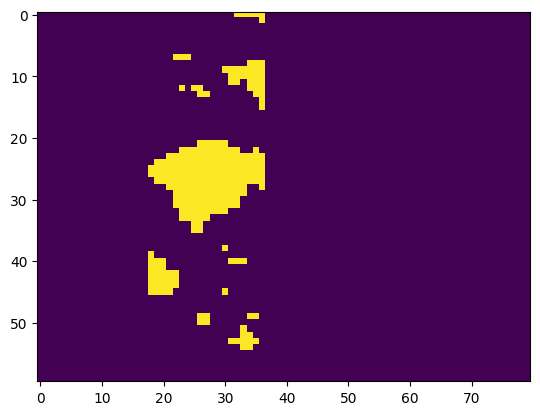

In [286]:
plt.imshow(clusters[0].reshape(movie.shape[2], movie.shape[1]).T)